# TSMOM หลายสินทรัพย์ (D1) + volatility targeting

เกณฑ์ผ่านล็อกไว้ใน `project/strategy/tsmom.py` ก่อนรัน **ห้ามแก้หลังเห็นผล**
- net Sharpe > 0.4, ปีที่กำไร >= 60%, max DD < 25%, stress (spread x2) Sharpe > 0.3
- lookback 126/189 ดูความเสถียรเท่านั้น ห้ามเลือกตัวที่ดีที่สุด
- นับจำนวนที่ลอง: **ครั้งที่ 1** ของกลยุทธ์ตระกูล TSMOM

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from datetime import datetime

import MetaTrader5 as mt5

from project.Untility.data_loader import DataLoader
from project.Untility.spread import fix_zero_spread
from project.strategy.tsmom import TsmomConfig, evaluate_pass, run_tsmom, metrics

# เริ่มด้วย 3 ตัว ถ้ามีเพิ่มใน Market Watch ใส่ต่อท้ายได้เลย (ยิ่งกระจายหลายกลุ่มยิ่งดี)
SYMBOLS = ["XAUUSD", "EURUSD", "US500"]
DATE_FROM, DATE_TO = datetime(2010, 1, 1), datetime(2024, 1, 1)

data, points = {}, {}
for s in SYMBOLS:
    loader = DataLoader(s, mt5.TIMEFRAME_D1)
    data[s] = loader.load_with_date(DATE_FROM, DATE_TO)
    points[s] = loader.point()
    print(
        s,
        len(data[s]),
        data[s].index.min().date(),
        data[s].index.max().date(),
        "point",
        points[s],
    )

XAUUSD 3606 2010-01-04 2023-12-29 point 0.01
EURUSD 3636 2010-01-04 2023-12-29 point 1e-05
US500 2947 2012-08-06 2023-12-29 point 0.01


In [3]:
# ผลตามเกณฑ์ที่ล็อกไว้ (รันครั้งเดียว อ่านผล ไม่ปรับแล้วรันซ้ำ)
out = evaluate_pass(data, points)
for k, v in out.items():
    print(k, ":", v)

base : {'sharpe': 0.25, 'return_%': 18.1, 'maxdd_%': 17.1, 'positive_years_%': 64.0, 'years': 11}
stress_spread_x2 : {'sharpe': 0.25, 'return_%': 17.8, 'maxdd_%': 17.1, 'positive_years_%': 64.0, 'years': 11}
lookback_stability_sharpe : {126: 0.41, 189: 0.24, 252: 0.25}
checks : {'sharpe > 0.4': False, 'positive years >= 60%': True, 'max DD < 25%': True, 'stress sharpe > 0.3': False}
pass : False
n_assets : 3


time
2013    6.1
2014    4.4
2015    1.8
2016   -6.4
2017    7.3
2018   -4.4
2019    3.2
2020    8.0
2021    1.4
2022   -2.3
2023   -1.2
Name: return_%, dtype: float64
ต้นทุนรวม (สัดส่วนของทุน): 0.0022
ผลก่อนหักต้นทุน: {'sharpe': 0.26, 'return_%': 18.4, 'maxdd_%': 17.0, 'positive_years_%': 64.0, 'years': 11}


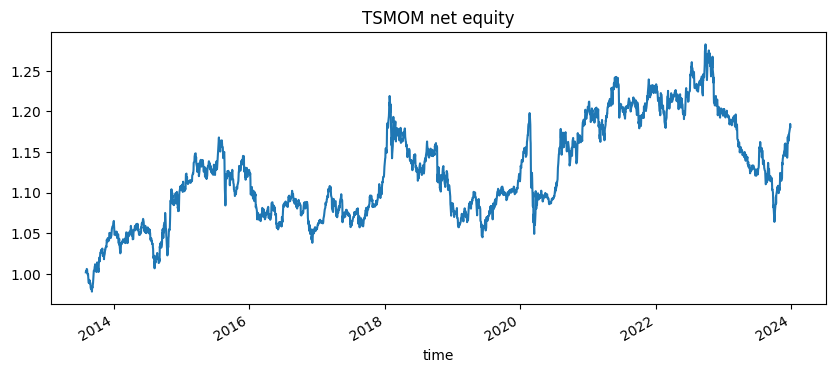

In [4]:
# ดูรายละเอียด: equity, น้ำหนักที่ถือ, ผลรายปี
res = run_tsmom(data, points)
res["equity"].plot(title="TSMOM net equity", figsize=(10, 4))
r = res["returns"]
print(((1 + r).groupby(r.index.year).prod() - 1).mul(100).round(1).rename("return_%"))
print("ต้นทุนรวม (สัดส่วนของทุน):", round(float(res["cost"].sum()), 4))
print("ผลก่อนหักต้นทุน:", metrics(res["gross_returns"]))

In [5]:
import MetaTrader5 as mt5

mt5.initialize()
names = [s.name for s in mt5.symbols_get()]
print(len(names), names[:200])
mt5.shutdown()

12269 ['AUDCAD', 'AUDCHF', 'AUDDKK', 'AUDHKD', 'AUDHUF', 'AUDJPY', 'AUDNOK', 'AUDNZD', 'AUDPLN', 'AUDSEK', 'AUDSGD', 'AUDTHB', 'AUDUSD', 'AUDZAR', 'CADCHF', 'CADDKK', 'CADJPY', 'CADMXN', 'CADNOK', 'CADPLN', 'CADSEK', 'CADSGD', 'CHFDKK', 'CHFHUF', 'CHFJPY', 'CHFMXN', 'CHFNOK', 'CHFPLN', 'CHFSEK', 'CHFSGD', 'CHFTRY', 'CHFZAR', 'CNHJPY', 'DKKJPY', 'DKKNOK', 'DKKSEK', 'EURAUD', 'EURCAD', 'EURCHF', 'EURCNH', 'EURCZK', 'EURDKK', 'EURGBP', 'EURHKD', 'EURHUF', 'EURILS', 'EURJPY', 'EURMXN', 'EURNOK', 'EURNZD', 'EURPLN', 'EURRUB', 'EURRUR', 'EURSEK', 'EURSGD', 'EURTRY', 'EURUSD', 'EURZAR', 'GBPAUD', 'GBPCAD', 'GBPCHF', 'GBPCZK', 'GBPDKK', 'GBPHKD', 'GBPHUF', 'GBPJPY', 'GBPMXN', 'GBPNOK', 'GBPNZD', 'GBPPLN', 'GBPSEK', 'GBPSGD', 'GBPTRY', 'GBPUSD', 'GBPZAR', 'HKDJPY', 'MXNJPY', 'NOKDKK', 'NOKJPY', 'NOKSEK', 'NZDCAD', 'NZDCHF', 'NZDDKK', 'NZDHUF', 'NZDJPY', 'NZDMXN', 'NZDNOK', 'NZDSEK', 'NZDSGD', 'NZDUSD', 'PLNJPY', 'SEKJPY', 'SEKNOK', 'SGDHKD', 'SGDJPY', 'TRYJPY', 'USDARS', 'USDBRL', 'USDCAD', 'US

True